# 🧠 Proje 1 · Bölüm 4 — Model nereye bakıyor? + Telefona taşıma
**Seviye: İleri**

Bir yapay zeka sistemine güvenmek için yalnızca *ne* dediğini değil, *neden* öyle dediğini de görmek isteriz. Bu bölümde:
1. **Sınıf Aktivasyon Haritası (CAM)** ile modelin kararında etkili olan bölgeleri ısı haritası olarak göstereceğiz.
2. Modeli **telefonda internetsiz çalışacak** biçimde dışa aktaracağız ve telefondaki sonucun Python'daki ile aynı olduğunu doğrulayacağız.

In [1]:
# Google Colab'da çalışıyorsanız: proje klasörünü (zip) yükleyip açın
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 01_Beyin_MR_Tumor.zip dosyasını seçin")
    yuklenen = files.upload()
    !unzip -q -o 01_Beyin_MR_Tumor.zip
    %cd 01_Beyin_MR_Tumor
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/01_Beyin_MR_Tumor


In [2]:
import os, json, base64, io
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, matplotlib.pyplot as plt, keras
from PIL import Image
plt.rcParams["figure.dpi"] = 110

model = keras.models.load_model("model/tumor_mobilenet.keras")
esik = json.load(open("model/esik.json"))["esik"]
d = np.load("islenmis/veri_128.npz", allow_pickle=True)
X, y, bolum, dosya = d["X"][..., None], d["y"], d["bolum"], d["dosya"]
tst_idx = np.where(bolum == "test")[0]
print("Karar eşiği:", round(esik, 3))

I0000 00:00:1791818712.297808   20948 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791818713.500641   20948 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Karar eşiği: 0.493


## 1. Sınıf Aktivasyon Haritası (CAM)
MobileNetV2'nin son katmanı görüntüyü 4×4'lük bir ızgarada 1280 farklı "desen dedektörü" ile özetler. Karar katmanının bu dedektörlere verdiği ağırlıklarla toplam alındığında, **"tümör" kararına katkı veren bölgeler** ortaya çıkar.

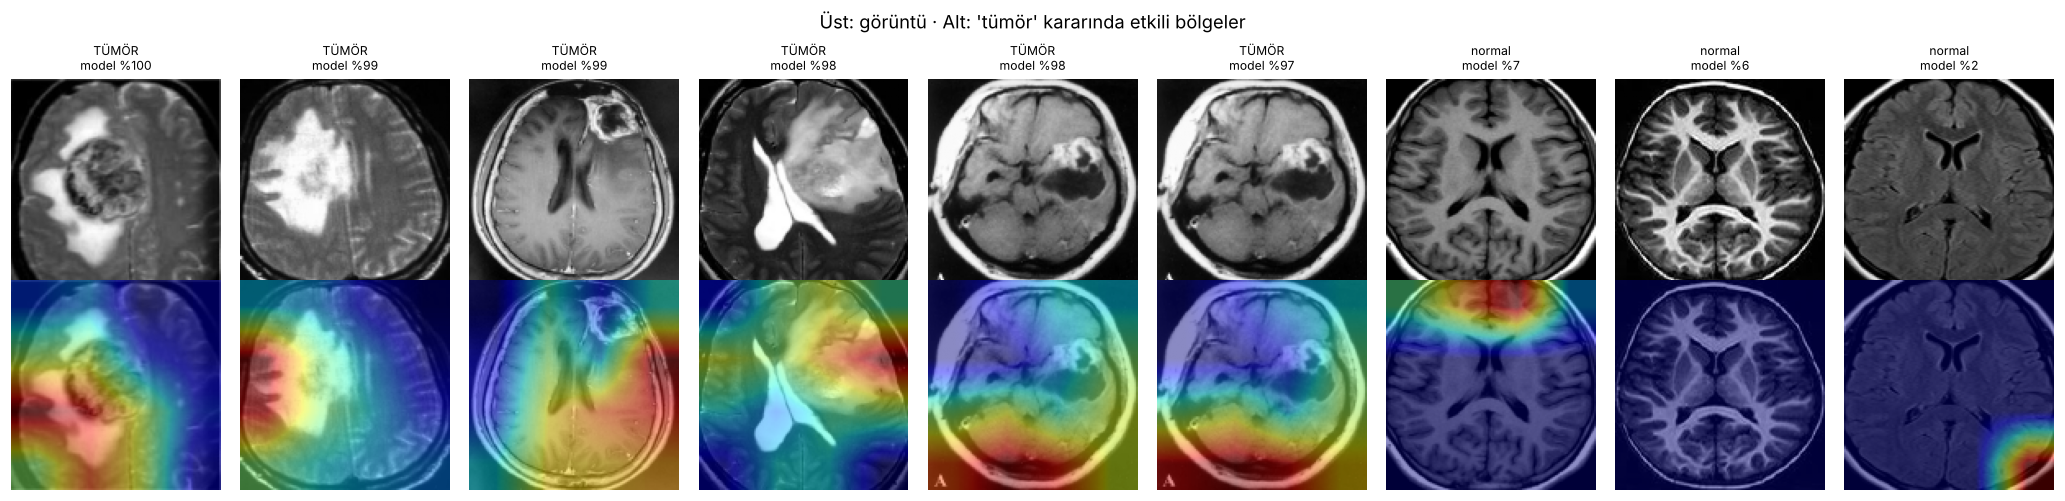

In [3]:
taban = next(L for L in model.layers if L.name.startswith("mobilenet"))
ozellik = keras.Model(model.input, taban(model.get_layer("olcekle").output))   # 4x4x1280 harita
w = model.get_layer("karar").get_weights()[0][:, 0]

def cam(x):
    A = ozellik(x[None], training=False).numpy()[0]
    c = np.maximum(A @ w, 0); c = c / (c.max() + 1e-8)
    return np.asarray(Image.fromarray((c * 255).astype(np.uint8)).resize((128, 128), Image.BILINEAR)) / 255.0

p_test = model.predict(X[tst_idx], verbose=0).ravel()
sirala = tst_idx[np.argsort(-p_test)]
secilen = list(sirala[:6]) + list(sirala[-3:])
fig, ax = plt.subplots(2, len(secilen), figsize=(2.1 * len(secilen), 4.6))
for k, i in enumerate(secilen):
    p = p_test[list(tst_idx).index(i)]
    ax[0, k].imshow(X[i, ..., 0], cmap="gray"); ax[0, k].set_title(f"{'TÜMÖR' if y[i] else 'normal'}\nmodel %{100*p:.0f}", fontsize=8)
    ax[1, k].imshow(X[i, ..., 0], cmap="gray"); ax[1, k].imshow(cam(X[i]), cmap="jet", alpha=0.45)
    for a in ax[:, k]: a.axis("off")
plt.suptitle("Üst: görüntü · Alt: 'tümör' kararında etkili bölgeler"); plt.tight_layout(); plt.show()

**Nasıl yorumlanmalı?** Isı haritası tümörün üzerindeyse iyi bir işaret. Kafatası kenarında, yazıda veya arka planda ise model **yanlış bir ipucu** (kısayol) öğrenmiş olabilir. Bu harita kesin bir **segmentasyon değildir**; kaba bir "dikkat" göstergesidir (4×4 ızgaradan büyütülür).

## 2. Telefona aktarma
Telefonlarda Python yoktur. Bu yüzden modelin öğrendiği sayıları (ağırlıkları) bir JavaScript dosyasına yazıyoruz. Uygulamadaki küçük bir motor (`yzmotor.js`) aynı hesaplamaları telefonda yapar. **Hiçbir görüntü cihaz dışına gönderilmez** (veri gizliliği / KVKK açısından önemli).

In [4]:
from yz_aktar import keras_to_js, js_ile_dogrula
bilgi = keras_to_js(model, "mobil/www/model.js", degisken="TUMOR_MODEL",
                    meta={"esik": esik, "girdi": "128x128 gri, 0-1", "egitim": "Brain MRI (Chakrabarty), 253 görüntü"})
print(bilgi)

{'dugum_sayisi': 106, 'boyut_kb': 2046}


## 3. Doğrulama: telefondaki motor Python ile aynı sonucu veriyor mu?
Test görüntülerini JavaScript motoruna (Node.js ile) verip olasılıkları karşılaştırıyoruz. **Mobil sağlık uygulamalarında bu adım zorunludur**: dönüştürme sırasında sessiz bir hata, modelin telefonda tamamen farklı davranmasına yol açabilir.

In [5]:
js = js_ile_dogrula("mobil/www/yzmotor.js", "mobil/www/model.js", "TUMOR_MODEL", X[tst_idx])
if js is None:
    print("Node.js bulunamadı; bu adım atlandı.")
else:
    js = js[:, 0]
    print(f"{len(js)} test görüntüsü | en büyük fark: {np.abs(js - p_test).max():.1e} | "
          f"karar uyumu: %{100*np.mean((js >= esik) == (p_test >= esik)):.0f}")

51 test görüntüsü | en büyük fark: 2.8e-06 | karar uyumu: %100


In [6]:
# Uygulama içine gömülecek örnek test görüntüleri (test setinden; eğitimde hiç görülmedi)
ornekler = []
for i in list(sirala[:3]) + list(sirala[-3:]):
    im = Image.open(str(dosya[i])).convert("RGB"); im.thumbnail((360, 360))
    tampon = io.BytesIO(); im.save(tampon, "JPEG", quality=88)
    ornekler.append({"ad": os.path.basename(str(dosya[i])), "etiket": "Tümör var" if y[i] else "Tümör yok",
                     "src": "data:image/jpeg;base64," + base64.b64encode(tampon.getvalue()).decode()})
with open("mobil/www/ornekler.js", "w") as f:
    f.write("window.ORNEKLER = " + json.dumps(ornekler, ensure_ascii=False) + ";\n")
print("Örnek görüntüler gömüldü:", [o["etiket"] for o in ornekler])

Örnek görüntüler gömüldü: ['Tümör var', 'Tümör var', 'Tümör var', 'Tümör yok', 'Tümör yok', 'Tümör yok']


## ✅ Sonuç
`mobil/` klasöründe uygulamanın tüm dosyaları var; `BeyinMR_YZ.apk` doğrudan Android telefona kurulabilir.

**Uygulama ne yapıyor?**
1. Galeriden bir MR kesiti seçilir (veya içindeki örneklerden biri).
2. Python'daki ön işlemenin aynısı uygulanır (kırpma, 128×128).
3. Model olasılığı hesaplar ve **ısı haritasını** görüntünün üzerine çizer.

💡 **Araştırma fikirleri**
* **Hekim + YZ** çalışması: Asistanların ısı haritasını görerek ve görmeden yaptığı okumaların doğruluk/süre karşılaştırması.
* **Cihaz üzerinde (on-device) YZ** ve veri gizliliği: Görüntü buluta gönderilmeden çalışan sistemlerin klinik kabulü.
* Isı haritalarının radyolog işaretlemeleriyle **örtüşme analizi** (açıklanabilirliğin güvenilirliği).